# Electrical Circuit Analysis with Linear Algebra

**Course:** SENG 201 – Linear Algebra (Level 200, Semester 1)
**Project type:** Course project – analytical and computational study
**Tools:** Python 3, NumPy and Matplotlib – everything runs in Google Colab with no extra installation.

---

## 1. Project description

Electrical circuits are everywhere in engineering: power supplies, sensors, audio amplifiers, filters and communication systems. Even a small circuit leads to **many equations in many unknowns**, and linear algebra is the language engineers use to write and solve them. This project analyses a set of realistic circuits using **every topic from SENG 201**. Results are worked out with formulas, computed with our own code, and cross-checked with NumPy.

### Problem statement
An electronics design team is developing a small circuit board. It contains a DC resistor network, an AC filter, an LED indicator and an amplifier stage. Before building it, the team must answer these questions:

1. **Components:** How do resistors and diodes behave, and how can their current–voltage laws be written and inverted as functions?
2. **DC operating point:** What voltage appears at every node and what current flows in every branch of the resistor network?
3. **Solvability:** When does the circuit have a unique solution, and why must one node be chosen as ground?
4. **Circuit structure:** Which current patterns are physically allowed? How can noisy current measurements be corrected so they obey Kirchhoff's laws?
5. **Switching behaviour:** How fast do capacitors charge and discharge?
6. **AC behaviour:** What are the amplitudes and phases of the voltages when the input is a sine wave, and how does the filter respond at different frequencies?
7. **Distortion:** Which extra frequencies (harmonics) does a slightly non-linear amplifier create?
8. **Natural response:** Will the circuit oscillate or settle smoothly after a disturbance, and at what frequencies do coupled circuits resonate?
9. **Cascaded stages:** How does a signal change as it passes through many identical stages?
10. **Safe design:** Which resistor values keep the LED current and resistor power within safe limits?

The task is to model each part of the board mathematically and answer every question using linear algebra and the supporting topics of the course.

### Objectives
1. Describe component laws as **functions**, including **exponential** and **logarithmic** functions and their inverses.
2. Write Kirchhoff's laws as **matrices** and **solve systems of linear equations** (Gaussian elimination, Cramer's rule, the inverse).
3. Use **determinants** to test for unique solutions and to count spanning trees of the circuit graph.
4. Identify **vector spaces and subspaces** (null space, row space) and use **orthogonality** (Tellegen's theorem, Gram–Schmidt, projection).
5. Analyse transients with **exponential and logarithmic functions**.
6. Analyse AC circuits with **complex numbers** and **trigonometric functions**.
7. Use the **binomial theorem** to predict amplifier distortion.
8. Use **eigenvalues and eigenvectors** to find natural responses and resonant modes.
9. Model two-port networks as **linear transformations**.
10. Solve **inequalities** to find safe component values.

### Course topics mapped to notebook sections

| # | Section | SENG 201 topics used |
|---|---|---|
| 2 | Component models | Functions and graphs, exponential and logarithmic functions, inverse functions, domain |
| 3 | DC circuit analysis | Matrices, systems of linear equations, Gaussian elimination, Cramer's rule, matrix inverse |
| 4 | Solvability and circuit graphs | Determinants, singular matrices, matrix-tree theorem |
| 5 | Circuit structure | Vector spaces, subspaces, null space, row space, rank–nullity, orthogonality, Gram–Schmidt, projection |
| 6 | Capacitor transients | Exponential and logarithmic functions |
| 7 | AC circuit analysis | Complex numbers (rectangular/polar forms, conjugates, Euler's formula), trigonometric functions, complex linear systems |
| 8 | Amplifier distortion | Binomial theorem, Pascal's triangle, De Moivre's theorem |
| 9 | Natural response and resonance | Eigenvalues, eigenvectors, diagonalisation, characteristic polynomial, orthogonal eigenvectors |
| 10 | Cascaded stages | Linear transformations, matrix multiplication, matrix powers, determinants |
| 11 | Safe LED design | Linear, absolute-value and logarithmic inequalities |
| 12 | Conclusion | Summary of results |

### How to run
Open this notebook in Google Colab and choose **Runtime → Run all**. Component values are defined at the top of each section, so you can change them and re-run.

## 1. Setup

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from math import comb

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(201)       # fixed seed so results are repeatable

## 2. Component models: functions, exponential and logarithmic functions

Each component is described by a **function** that gives its current $I$ for a voltage $V$.

| Component | Function | Type |
|---|---|---|
| Resistor | $I = f(V) = \dfrac{V}{R}$ | linear |
| Diode | $I = g(V) = I_S\left(e^{V/(nV_T)} - 1\right)$ | exponential |
| Diode (inverse) | $V = g^{-1}(I) = nV_T \ln\!\left(1 + \dfrac{I}{I_S}\right)$ | logarithmic, domain $I > -I_S$ |

The logarithm is the **inverse** of the exponential, so $g^{-1}(g(V)) = V$. Taking logs also turns the exponential curve into a **straight line**: for $V \gg nV_T$,
$$\ln I \approx \ln I_S + \frac{1}{nV_T}\,V .$$

In [27]:
IS, N_IDEAL, VT = 1e-12, 1.0, 0.02585     # saturation current (A), ideality factor, thermal voltage (V)

def resistor_current(v, r=100.0):
    return v / r

def diode_current(v):
    return IS * (np.exp(v / (N_IDEAL * VT)) - 1)

def diode_voltage(i):
    # Inverse function; only defined when 1 + i/IS > 0, i.e. i > -IS
    return N_IDEAL * VT * np.log(1 + i / IS)

for v in [0.3, 0.5, 0.6, 0.65]:
    i = diode_current(v)
    print(f"V = {v:.2f} V  ->  I = g(V) = {i:.4e} A  ->  g⁻¹(I) = {diode_voltage(i):.4f} V")

V = 0.30 V  ->  I = g(V) = 1.0969e-07 A  ->  g⁻¹(I) = 0.3000 V
V = 0.50 V  ->  I = g(V) = 2.5135e-04 A  ->  g⁻¹(I) = 0.5000 V
V = 0.60 V  ->  I = g(V) = 1.2032e-02 A  ->  g⁻¹(I) = 0.6000 V
V = 0.65 V  ->  I = g(V) = 8.3246e-02 A  ->  g⁻¹(I) = 0.6500 V


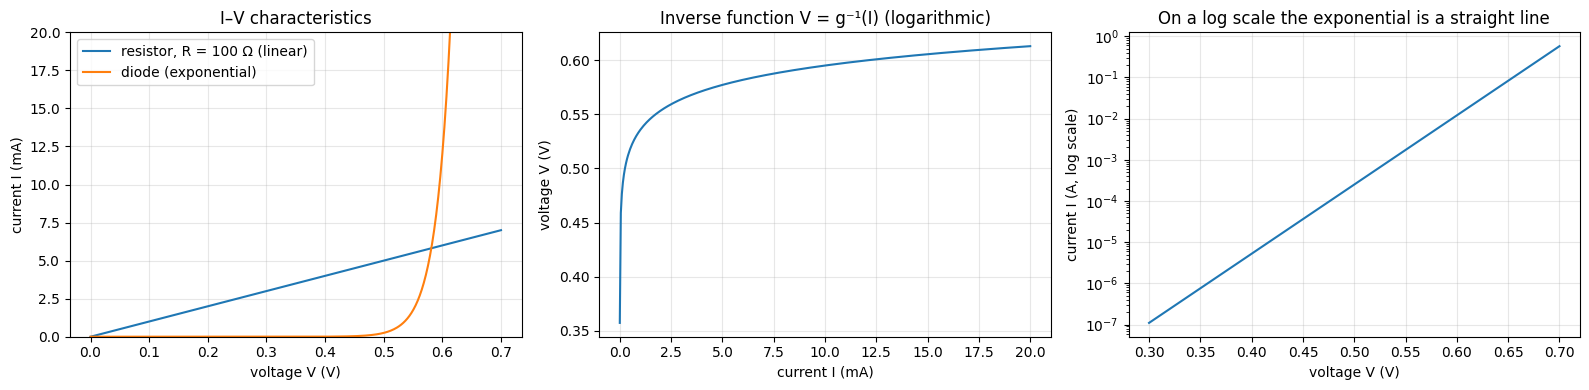

In [28]:
v = np.linspace(0, 0.7, 400)
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].plot(v, 1e3 * resistor_current(v), label="resistor, R = 100 Ω (linear)")
axs[0].plot(v, 1e3 * diode_current(v), label="diode (exponential)")
axs[0].set(xlabel="voltage V (V)", ylabel="current I (mA)", title="I–V characteristics", ylim=(0, 20))
axs[0].legend()

i = np.linspace(1e-6, 0.02, 400)
axs[1].plot(1e3 * i, diode_voltage(i))
axs[1].set(xlabel="current I (mA)", ylabel="voltage V (V)", title="Inverse function V = g⁻¹(I) (logarithmic)")

v_fwd = np.linspace(0.3, 0.7, 100)
axs[2].semilogy(v_fwd, diode_current(v_fwd))
axs[2].set(xlabel="voltage V (V)", ylabel="current I (A, log scale)", title="On a log scale the exponential is a straight line")
plt.tight_layout()
plt.show()

**Recovering $V_T$ with a linear system.** We take noisy "measurements" of $\ln I$ at several voltages and fit the line $\ln I = c_0 + c_1 V$. The best fit solves the **normal equations** $(X^{\mathsf T}X)\,\mathbf c = X^{\mathsf T}\mathbf y$, a $2\times2$ linear system. The slope gives $nV_T = 1/c_1$.

In [29]:
v_meas = np.linspace(0.40, 0.65, 12)
ln_i_meas = np.log(diode_current(v_meas)) + rng.normal(0, 0.05, v_meas.size)

X = np.column_stack([np.ones_like(v_meas), v_meas])
c = np.linalg.solve(X.T @ X, X.T @ ln_i_meas)
print("Normal equations  (XᵀX) c = Xᵀy  with  XᵀX =\n", X.T @ X)
print(f"Fitted line: ln I = {c[0]:.3f} + {c[1]:.3f} V")
print(f"Estimated n·V_T = 1/c1 = {1/c[1]:.5f} V  (true {N_IDEAL*VT:.5f} V)")
print(f"Estimated I_S = e^c0 = {np.exp(c[0]):.3e} A  (true {IS:.1e} A)")

Normal equations  (XᵀX) c = Xᵀy  with  XᵀX =
 [[12.      6.3   ]
 [ 6.3     3.3814]]
Fitted line: ln I = -27.705 + 38.851 V
Estimated n·V_T = 1/c1 = 0.02574 V  (true 0.02585 V)
Estimated I_S = e^c0 = 9.284e-13 A  (true 1.0e-12 A)


## 3. DC circuit analysis: matrices and systems of linear equations

### The circuit
Four nodes (0 = ground, 1, 2, 3) are joined by six branches:

| Branch | From → To | Resistance | Source |
|---|---|---|---|
| b1 | 1 → 0 | 2 Ω | 12 V battery (+ terminal towards node 1) |
| b2 | 1 → 2 | 4 Ω | – |
| b3 | 1 → 3 | 8 Ω | – |
| b4 | 2 → 3 | 5 Ω | – |
| b5 | 2 → 0 | 10 Ω | – |
| b6 | 3 → 0 | 6 Ω | – |

### Matrix formulation
* The **incidence matrix** $A$ has one row per node and one column per branch: $+1$ where a branch leaves a node and $-1$ where it enters. We remove the ground row to get the reduced matrix.
* Node voltages $\mathbf e$ give branch voltages $\mathbf v = A^{\mathsf T}\mathbf e$ (**KVL**).
* Each branch obeys Ohm's law with its source: $\mathbf i = G(\mathbf v - \mathbf v_s)$, where $G$ is the diagonal matrix of conductances $1/R$.
* **KCL** (current in = current out at every node) is $A\,\mathbf i = \mathbf 0$.

Putting these together gives a **system of linear equations** for the node voltages:
$$\underbrace{A\,G\,A^{\mathsf T}}_{Y}\;\mathbf e = A\,G\,\mathbf v_s .$$

In [30]:
# (from_node, to_node, resistance in ohms, source voltage in volts)
branches = [
    (1, 0, 2.0, 12.0),
    (1, 2, 4.0, 0.0),
    (1, 3, 8.0, 0.0),
    (2, 3, 5.0, 0.0),
    (2, 0, 10.0, 0.0),
    (3, 0, 6.0, 0.0),
]
N_NODES, N_BR = 4, len(branches)

A_full = np.zeros((N_NODES, N_BR))
for k, (a, b, _, _) in enumerate(branches):
    A_full[a, k] = 1.0       # branch leaves node a
    A_full[b, k] = -1.0      # branch enters node b
A = A_full[1:]               # reduced incidence matrix (ground row removed)

G = np.diag([1 / r for _, _, r, _ in branches])
v_s = np.array([s for _, _, _, s in branches])

Y = A @ G @ A.T
rhs = A @ G @ v_s
print("Reduced incidence matrix A =\n", A)
print("\nNodal matrix Y = A G Aᵀ =\n", Y)
print("\nRight-hand side A G v_s =", rhs)
print("Y is symmetric:", np.allclose(Y, Y.T))

Reduced incidence matrix A =
 [[ 1.  1.  1.  0.  0.  0.]
 [ 0. -1.  0.  1.  1.  0.]
 [ 0.  0. -1. -1.  0.  1.]]

Nodal matrix Y = A G Aᵀ =
 [[ 0.875  -0.25   -0.125 ]
 [-0.25    0.55   -0.2   ]
 [-0.125  -0.2     0.4917]]

Right-hand side A G v_s = [6. 0. 0.]
Y is symmetric: True


### Solving $Y\mathbf e = \mathbf b$ in four ways
1. **Gaussian elimination** with partial pivoting and back substitution (our own code)
2. **Cramer's rule:** $e_k = \det(Y_k)/\det(Y)$, where $Y_k$ is $Y$ with column $k$ replaced by $\mathbf b$
3. **Matrix inverse:** $\mathbf e = Y^{-1}\mathbf b$
4. **NumPy:** `np.linalg.solve`

In [31]:
def gaussian_elimination(M, b):
    M = M.astype(complex if np.iscomplexobj(M) or np.iscomplexobj(b) else float).copy()
    b = b.astype(M.dtype).copy()
    n = len(b)
    for col in range(n):
        p = col + np.argmax(np.abs(M[col:, col]))          # partial pivoting
        if np.isclose(abs(M[p, col]), 0):
            raise ValueError("matrix is singular - no unique solution")
        M[[col, p]], b[[col, p]] = M[[p, col]], b[[p, col]]
        for row in range(col + 1, n):
            factor = M[row, col] / M[col, col]
            M[row, col:] -= factor * M[col, col:]
            b[row] -= factor * b[col]
    x = np.zeros(n, dtype=M.dtype)
    for i in range(n - 1, -1, -1):                          # back substitution
        x[i] = (b[i] - M[i, i + 1:] @ x[i + 1:]) / M[i, i]
    return x

def cramer(M, b):
    D = np.linalg.det(M)
    if np.isclose(abs(D), 0):
        raise ValueError("det = 0 - Cramer's rule cannot be used")
    x = []
    for k in range(len(b)):
        Mk = M.astype(complex if np.iscomplexobj(b) else M.dtype).copy()
        Mk[:, k] = b
        x.append(np.linalg.det(Mk) / D)
    return np.array(x)

solutions = {
    "Gaussian elimination": gaussian_elimination(Y, rhs),
    "Cramer's rule": cramer(Y, rhs),
    "Inverse Y⁻¹ b": np.linalg.inv(Y) @ rhs,
    "numpy.linalg.solve": np.linalg.solve(Y, rhs),
}
for name, sol in solutions.items():
    print(f"{name:22s} e1 = {sol[0]:8.4f} V   e2 = {sol[1]:8.4f} V   e3 = {sol[2]:8.4f} V")
e = solutions["numpy.linalg.solve"]

Gaussian elimination   e1 =   9.2295 V   e2 =   5.9249 V   e3 =   4.7566 V
Cramer's rule          e1 =   9.2295 V   e2 =   5.9249 V   e3 =   4.7566 V
Inverse Y⁻¹ b          e1 =   9.2295 V   e2 =   5.9249 V   e3 =   4.7566 V
numpy.linalg.solve     e1 =   9.2295 V   e2 =   5.9249 V   e3 =   4.7566 V


In [32]:
v_br = A.T @ e                    # branch voltages (KVL)
i_br = G @ (v_br - v_s)           # branch currents (Ohm's law with source)

print("Branch   from→to    voltage (V)   current (A)   power in resistor (W)")
for k, (a, b, r, _) in enumerate(branches):
    print(f"  b{k+1}      {a} → {b}    {v_br[k]:10.4f}   {i_br[k]:11.4f}   {r * i_br[k]**2:12.4f}")

print("\nKCL check  A·i =", A @ i_br, "(should be zero)")
p_source = branches[0][3] * (-i_br[0])
p_resistors = sum(r * i_br[k] ** 2 for k, (_, _, r, _) in enumerate(branches))
print(f"Power delivered by the battery = {p_source:.4f} W")
print(f"Power dissipated in resistors  = {p_resistors:.4f} W")

Branch   from→to    voltage (V)   current (A)   power in resistor (W)
  b1      1 → 0        9.2295       -1.3853         3.8379
  b2      1 → 2        3.3046        0.8261         2.7301
  b3      1 → 3        4.4729        0.5591         2.5008
  b4      2 → 3        1.1683        0.2337         0.2730
  b5      2 → 0        5.9249        0.5925         3.5104
  b6      3 → 0        4.7566        0.7928         3.7709

KCL check  A·i = [ 0. -0. -0.] (should be zero)
Power delivered by the battery = 16.6231 W
Power dissipated in resistors  = 16.6231 W


## 4. Solvability and circuit graphs: determinants

### 4.1 Why we need a ground node
A square system has a **unique solution exactly when its determinant is non-zero**. If we keep all four nodes (no ground), the matrix $L = A_{\text{full}}\,G\,A_{\text{full}}^{\mathsf T}$ is **singular**. Adding the same constant to every node voltage changes no current, so $L\,[1,1,1,1]^{\mathsf T} = \mathbf 0$. Fixing node 0 at 0 V removes this freedom.

In [33]:
L_full = A_full @ G @ A_full.T
print(f"det(Y) with ground chosen     = {np.linalg.det(Y):.4f}   (non-zero -> unique solution)")
print(f"det(L) without a ground node  = {np.linalg.det(L_full):.2e}   (zero -> singular)")
print("L · [1, 1, 1, 1] =", L_full @ np.ones(N_NODES))
print(f"rank(L) = {np.linalg.matrix_rank(L_full)} out of {N_NODES}")

det(Y) with ground chosen     = 0.1498   (non-zero -> unique solution)
det(L) without a ground node  = -8.32e-18   (zero -> singular)
L · [1, 1, 1, 1] = [0. 0. 0. 0.]
rank(L) = 3 out of 4


### 4.2 Counting spanning trees with a determinant
A **spanning tree** is a set of branches that connects every node without forming a loop. Engineers use trees to choose independent equations. The **matrix-tree theorem** says:
$$\#\text{spanning trees} = \det\!\left(A A^{\mathsf T}\right).$$
We check this by brute force. A tree here has $N-1 = 3$ branches, so there are $\binom{6}{3}$ candidate sets. A set is a tree exactly when its $3\times3$ sub-matrix of $A$ has a **non-zero determinant**.

In [34]:
trees = []
for subset in combinations(range(N_BR), N_NODES - 1):
    if abs(np.linalg.det(A[:, list(subset)])) > 0.5:
        trees.append(subset)

print(f"Candidate branch sets: C({N_BR},{N_NODES-1}) = {comb(N_BR, N_NODES-1)}")
print(f"Spanning trees found by brute force: {len(trees)}")
print(f"det(A Aᵀ) = {np.linalg.det(A @ A.T):.4f}")
print("Branch sets that are NOT trees (they contain a loop):",
      [tuple(f"b{k+1}" for k in s) for s in combinations(range(N_BR), N_NODES - 1) if s not in trees])

Candidate branch sets: C(6,3) = 20
Spanning trees found by brute force: 16
det(A Aᵀ) = 16.0000
Branch sets that are NOT trees (they contain a loop): [('b1', 'b2', 'b5'), ('b1', 'b3', 'b6'), ('b2', 'b3', 'b4'), ('b4', 'b5', 'b6')]


## 5. Circuit structure: vector spaces, subspaces and orthogonality

Branch currents live in $\mathbb R^6$, but not every vector is physically possible.
* **Allowed currents** satisfy KCL, $A\,\mathbf i = \mathbf 0$. They form the **null space** $N(A)$, a **subspace** of $\mathbb R^6$. Its vectors are combinations of **loop currents**.
* **Allowed voltages** satisfy KVL, $\mathbf v = A^{\mathsf T}\mathbf e$. They form the **row space** $C(A^{\mathsf T})$.
* **Rank–nullity:** $\operatorname{rank}(A) + \dim N(A) = 6$. So the number of independent loops is $b - n + 1$.
* The row space and the null space are **orthogonal complements**. So *every* allowed voltage vector is orthogonal to *every* allowed current vector: $\mathbf v^{\mathsf T}\mathbf i = 0$. This is **Tellegen's theorem**, and it is why total power always balances.

In [35]:
rank = np.linalg.matrix_rank(A)
_, sing, Vt = np.linalg.svd(A)
null_basis = Vt[rank:].T                       # orthonormal basis of N(A) from the SVD
print(f"rank(A) = {rank},  dim N(A) = {null_basis.shape[1]},  rank + nullity = {rank + null_basis.shape[1]} = number of branches")
print(f"Independent loops = b - n + 1 = {N_BR} - {N_NODES} + 1 = {N_BR - N_NODES + 1}")

# Three loops found by hand (+1 = traversed along the branch direction, -1 = against it)
loops = np.array([
    [-1, 1, 0, 0, 1, 0],    # 0 → 1 → 2 → 0
    [0, 1, -1, 1, 0, 0],    # 1 → 2 → 3 → 1
    [0, 0, 0, 1, -1, 1],    # 0 → 2 → 3 → 0
], dtype=float).T
print("\nA · loops =\n", A @ loops, "\n(zero: each loop current is in the null space)")
print("Loops are linearly independent:", np.linalg.matrix_rank(loops) == 3)
print("They span the same subspace as the SVD basis:",
      np.linalg.matrix_rank(np.hstack([loops, null_basis])) == 3)

rank(A) = 3,  dim N(A) = 3,  rank + nullity = 6 = number of branches
Independent loops = b - n + 1 = 6 - 4 + 1 = 3

A · loops =
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]] 
(zero: each loop current is in the null space)
Loops are linearly independent: True
They span the same subspace as the SVD basis: True


In [36]:
# Orthogonality checks
print("Solved branch currents are in N(A):", np.allclose(A @ i_br, 0))
print("Solved branch voltages satisfy KVL around every loop:", np.allclose(loops.T @ v_br, 0))
print(f"Tellegen's theorem  vᵀi = {v_br @ i_br:.2e}  (orthogonal vectors)")

# Every row of A (a basis of the row space) is orthogonal to every loop
print("Row space ⟂ null space:  A · null_basis =\n", A @ null_basis)

Solved branch currents are in N(A): True
Solved branch voltages satisfy KVL around every loop: True
Tellegen's theorem  vᵀi = 1.33e-15  (orthogonal vectors)
Row space ⟂ null space:  A · null_basis =
 [[ 0.  0.  0.]
 [-0. -0.  0.]
 [ 0. -0.  0.]]


### Gram–Schmidt and orthogonal projection: cleaning noisy measurements
Measured currents always contain errors, so they break KCL slightly. The best correction is the **orthogonal projection** onto the subspace of allowed currents:
$$\hat{\mathbf i} = P\,\mathbf i_{\text{meas}}, \qquad P = QQ^{\mathsf T},$$
where the columns of $Q$ are an **orthonormal basis** of $N(A)$, found with **Gram–Schmidt** from the hand-made loops. As a check, $P$ must equal $I - A^{\mathsf T}(AA^{\mathsf T})^{-1}A$.

In [37]:
def gram_schmidt(V):
    Q = np.zeros_like(V, dtype=float)
    for j in range(V.shape[1]):
        w = V[:, j].astype(float)
        for k in range(j):
            w = w - (Q[:, k] @ V[:, j]) * Q[:, k]     # remove components along earlier vectors
        Q[:, j] = w / np.linalg.norm(w)
    return Q

Q = gram_schmidt(loops)
print("QᵀQ =\n", Q.T @ Q, "\n(identity: the columns are orthonormal)")

P = Q @ Q.T
P_check = np.eye(N_BR) - A.T @ np.linalg.inv(A @ A.T) @ A
print("P = QQᵀ equals I - Aᵀ(AAᵀ)⁻¹A:", np.allclose(P, P_check))
print("P is a projection (P² = P) and symmetric:", np.allclose(P @ P, P), np.allclose(P, P.T))

i_meas = i_br + rng.normal(0, 0.05, N_BR)       # noisy ammeter readings
i_clean = P @ i_meas
print(f"\nKCL violation  |A·i|: measured = {np.linalg.norm(A @ i_meas):.4f},  projected = {np.linalg.norm(A @ i_clean):.2e}")
print(f"Error vs true currents: measured = {np.linalg.norm(i_meas - i_br):.4f},  projected = {np.linalg.norm(i_clean - i_br):.4f}")
print(f"The removed part is orthogonal to the subspace: {np.allclose(Q.T @ (i_meas - i_clean), 0)}")

QᵀQ =
 [[ 1. -0.  0.]
 [-0.  1.  0.]
 [ 0.  0.  1.]] 
(identity: the columns are orthonormal)
P = QQᵀ equals I - Aᵀ(AAᵀ)⁻¹A: True
P is a projection (P² = P) and symmetric: True True

KCL violation  |A·i|: measured = 0.1366,  projected = 1.57e-16
Error vs true currents: measured = 0.1385,  projected = 0.1204
The removed part is orthogonal to the subspace: True


## 6. Capacitor transients: exponential and logarithmic functions

When a capacitor $C$ charges through a resistor $R$ from a supply $V_s$:
$$v_C(t) = V_s\left(1 - e^{-t/\tau}\right), \qquad \tau = RC .$$
When it discharges: $v_C(t) = V_s e^{-t/\tau}$.

Logarithms answer the inverse question, "how long until the voltage reaches a given level?":
$$t = -\tau \ln\!\left(1 - \frac{v}{V_s}\right) \quad\Rightarrow\quad t_{90\%} = \tau\ln 10 .$$

Time constant τ = RC = 0.100 s
  after 1τ: charged to  63.21 % of V_s
  after 2τ: charged to  86.47 % of V_s
  after 3τ: charged to  95.02 % of V_s
  after 4τ: charged to  98.17 % of V_s
  after 5τ: charged to  99.33 % of V_s

Time to reach 90 %: τ·ln(10) = 0.2303 s   check: v(t90) = 4.5000 V
Measured v(0.05) = 1.9673 V  ->  τ = -t / ln(1 - v/V_s) = 0.1000 s


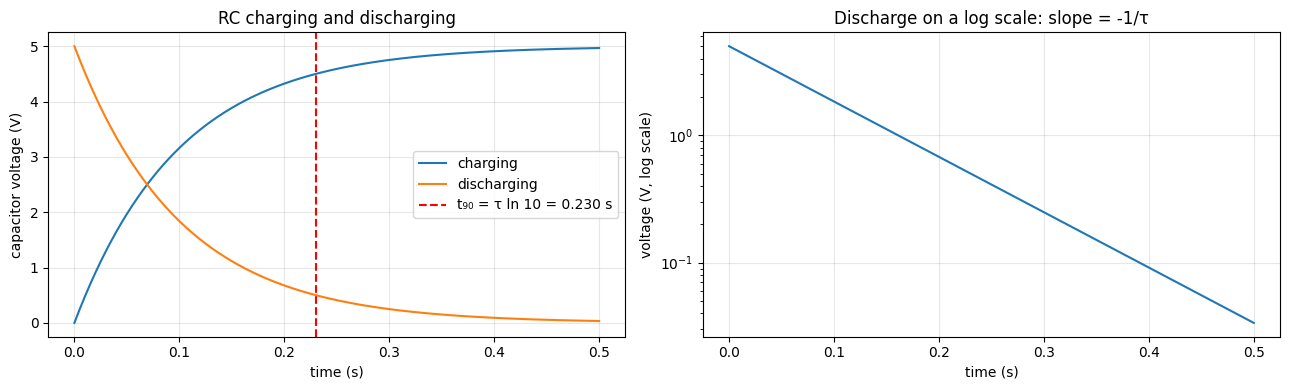

In [13]:
R_RC, C_RC, VS_RC = 1e3, 100e-6, 5.0
tau = R_RC * C_RC
t = np.linspace(0, 5 * tau, 500)
v_charge = VS_RC * (1 - np.exp(-t / tau))
v_discharge = VS_RC * np.exp(-t / tau)

print(f"Time constant τ = RC = {tau:.3f} s")
for m in range(1, 6):
    print(f"  after {m}τ: charged to {100*(1 - np.exp(-m)):6.2f} % of V_s")
t90 = tau * np.log(10)
print(f"\nTime to reach 90 %: τ·ln(10) = {t90:.4f} s   check: v(t90) = {VS_RC*(1 - np.exp(-t90/tau)):.4f} V")

# Inverse problem: estimate τ from a single measurement using the logarithm
t_m, v_m = 0.05, VS_RC * (1 - np.exp(-0.05 / tau))
print(f"Measured v({t_m}) = {v_m:.4f} V  ->  τ = -t / ln(1 - v/V_s) = {-t_m / np.log(1 - v_m / VS_RC):.4f} s")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(t, v_charge, label="charging")
axs[0].plot(t, v_discharge, label="discharging")
axs[0].axvline(t90, color="r", ls="--", label=f"t₉₀ = τ ln 10 = {t90:.3f} s")
axs[0].set(xlabel="time (s)", ylabel="capacitor voltage (V)", title="RC charging and discharging")
axs[0].legend()
axs[1].semilogy(t, v_discharge)
axs[1].set(xlabel="time (s)", ylabel="voltage (V, log scale)", title="Discharge on a log scale: slope = -1/τ")
plt.tight_layout()
plt.show()

## 7. AC circuit analysis: complex numbers and trigonometric functions

A sinusoidal voltage $v(t) = V_m\cos(\omega t + \phi)$ is represented by the **phasor** $\mathbf V = V_m e^{j\phi}$, a complex number. By **Euler's formula**, $e^{j\theta} = \cos\theta + j\sin\theta$, so
$$v(t) = \operatorname{Re}\!\left(\mathbf V e^{j\omega t}\right).$$
Each component becomes a complex **impedance**: $Z_R = R$, $Z_L = j\omega L$, $Z_C = \dfrac{1}{j\omega C}$.

### The filter circuit
A 10 V, 50 Hz source with series resistor $R_1$ feeds node 1. A capacitor $C$ connects node 1 to ground. An inductor $L$ connects node 1 to node 2, and a load $R_2$ connects node 2 to ground. Nodal analysis gives a **complex** $2\times2$ linear system:
$$\begin{pmatrix} \frac1{R_1} + j\omega C + \frac1{j\omega L} & -\frac1{j\omega L} \\ -\frac1{j\omega L} & \frac1{j\omega L} + \frac1{R_2}\end{pmatrix}\begin{pmatrix}\mathbf V_1\\ \mathbf V_2\end{pmatrix} = \begin{pmatrix}\mathbf V_s/R_1\\ 0\end{pmatrix}.$$

In [38]:
R1, R2, L_AC, C_AC = 100.0, 50.0, 0.1, 50e-6
VS_AC = 10.0 + 0j               # phasor of the source (10 V peak, phase 0)
F_AC = 50.0
W_AC = 2 * np.pi * F_AC

def ac_system(w):
    yl, yc = 1 / (1j * w * L_AC), 1j * w * C_AC
    Ymat = np.array([[1 / R1 + yc + yl, -yl],
                     [-yl, yl + 1 / R2]], dtype=complex)
    b = np.array([VS_AC / R1, 0], dtype=complex)
    return Ymat, b

Y_ac, b_ac = ac_system(W_AC)
V_ac = np.linalg.solve(Y_ac, b_ac)
print(f"Impedances at {F_AC} Hz:  Z_L = {1j*W_AC*L_AC:.2f} Ω,  Z_C = {1/(1j*W_AC*C_AC):.2f} Ω")
print("Complex nodal matrix =\n", Y_ac)
print(f"\ndet = {np.linalg.det(Y_ac):.6f}  (non-zero -> unique solution)")
for name, sol in [("numpy.linalg.solve", V_ac), ("Gaussian elimination", gaussian_elimination(Y_ac, b_ac)),
                  ("Cramer's rule", cramer(Y_ac, b_ac))]:
    print(f"{name:21s} V1 = {sol[0]:.4f} V,  V2 = {sol[1]:.4f} V")

print("\nRectangular → polar form:")
for name, ph in [("V1", V_ac[0]), ("V2", V_ac[1])]:
    print(f"  {name} = {ph.real:+.4f} {ph.imag:+.4f}j  =  {abs(ph):.4f} ∠ {np.degrees(np.angle(ph)):+.2f}°")

Impedances at 50.0 Hz:  Z_L = 0.00+31.42j Ω,  Z_C = 0.00-63.66j Ω
Complex nodal matrix =
 [[ 0.01-0.0161j -0.  +0.0318j]
 [-0.  +0.0318j  0.02-0.0318j]]

det = 0.000700-0.000641j  (non-zero -> unique solution)
numpy.linalg.solve    V1 = 3.8193-1.0511j V,  V2 = 2.2648-2.4741j V
Gaussian elimination  V1 = 3.8193-1.0511j V,  V2 = 2.2648-2.4741j V
Cramer's rule         V1 = 3.8193-1.0511j V,  V2 = 2.2648-2.4741j V

Rectangular → polar form:
  V1 = +3.8193 -1.0511j  =  3.9613 ∠ -15.39°
  V2 = +2.2648 -2.4741j  =  3.3542 ∠ -47.53°


Source current I = 0.0627 A ∠ +9.65°
Complex power S = ½ V I* = 0.3090-0.0526j  ->  real power P = 0.3090 W, reactive power Q = -0.0526 var
Power used by R1 + R2 = 0.3090 W (matches P)
|I|² = I·I* check: 0.003931 = 0.003931

Euler: e^(j0.7) = 0.764842+0.644218j,  cos 0.7 + j sin 0.7 = 0.764842+0.644218j
Three forms of v2(t) agree: True


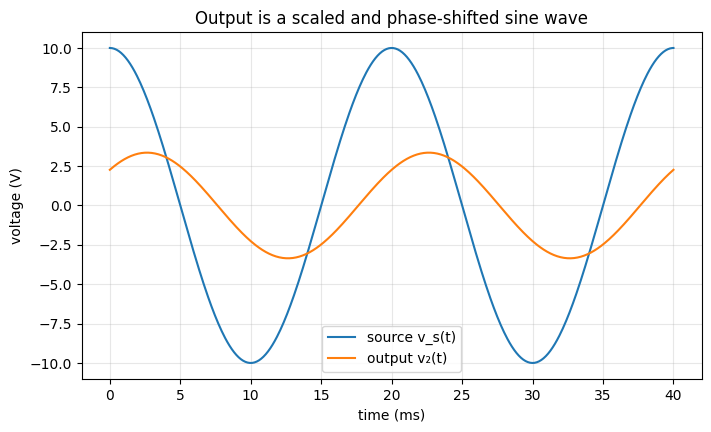

In [15]:
I_src = (VS_AC - V_ac[0]) / R1
S = 0.5 * VS_AC * np.conj(I_src)              # complex power (peak phasors), uses the conjugate
p_r1 = 0.5 * abs(I_src) ** 2 * R1
p_r2 = 0.5 * abs(V_ac[1]) ** 2 / R2
print(f"Source current I = {abs(I_src):.4f} A ∠ {np.degrees(np.angle(I_src)):+.2f}°")
print(f"Complex power S = ½ V I* = {S:.4f}  ->  real power P = {S.real:.4f} W, reactive power Q = {S.imag:.4f} var")
print(f"Power used by R1 + R2 = {p_r1 + p_r2:.4f} W (matches P)")
print(f"|I|² = I·I* check: {abs(I_src)**2:.6f} = {(I_src*np.conj(I_src)).real:.6f}")

# Euler's formula and the trigonometric form of the waveform
theta = 0.7
print(f"\nEuler: e^(j0.7) = {np.exp(1j*theta):.6f},  cos 0.7 + j sin 0.7 = {complex(np.cos(theta), np.sin(theta)):.6f}")

t = np.linspace(0, 2 / F_AC, 500)
a, b = V_ac[1].real, V_ac[1].imag
v2_polar = abs(V_ac[1]) * np.cos(W_AC * t + np.angle(V_ac[1]))
v2_trig = a * np.cos(W_AC * t) - b * np.sin(W_AC * t)      # cos(x + y) = cos x cos y - sin x sin y
v2_euler = (V_ac[1] * np.exp(1j * W_AC * t)).real
print("Three forms of v2(t) agree:", np.allclose(v2_polar, v2_trig) and np.allclose(v2_polar, v2_euler))

plt.plot(1e3 * t, (VS_AC * np.exp(1j * W_AC * t)).real, label="source v_s(t)")
plt.plot(1e3 * t, v2_polar, label="output v₂(t)")
plt.xlabel("time (ms)")
plt.ylabel("voltage (V)")
plt.title("Output is a scaled and phase-shifted sine wave")
plt.legend()
plt.show()

### Frequency response
Solving the complex system at many frequencies gives the **transfer function** $H(f) = \mathbf V_2/\mathbf V_s$. Engineers plot it against a **logarithmic** frequency axis, with gain measured in decibels: $20\log_{10}|H|$.

DC gain (L = short, C = open) = R2/(R1+R2) = 0.3333
-3 dB cut-off frequency ≈ 97.3 Hz


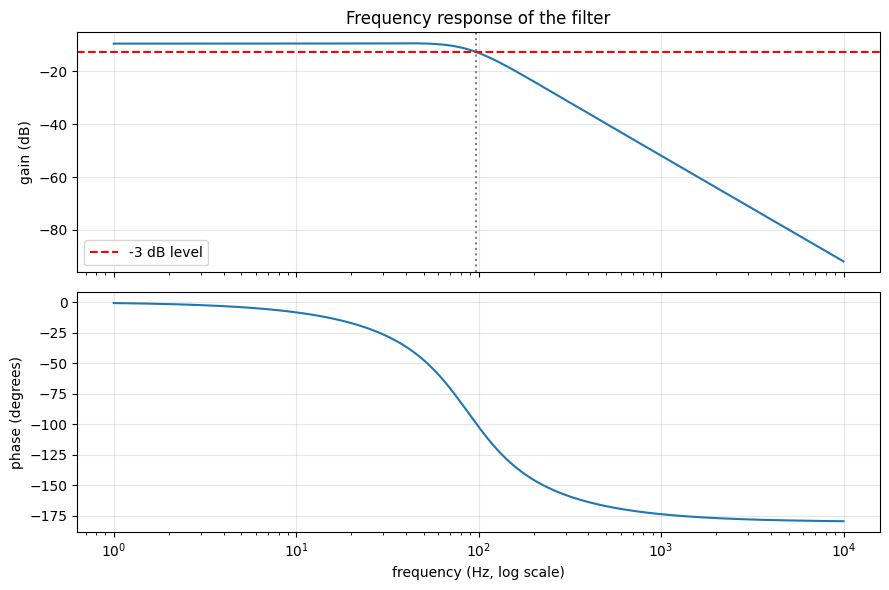

In [16]:
freqs = np.logspace(0, 4, 500)          # 1 Hz to 10 kHz
H = np.array([np.linalg.solve(*ac_system(2 * np.pi * f))[1] / VS_AC for f in freqs])
dc_gain = R2 / (R1 + R2)
idx = np.argmax(np.abs(H) < dc_gain / np.sqrt(2))
print(f"DC gain (L = short, C = open) = R2/(R1+R2) = {dc_gain:.4f}")
print(f"-3 dB cut-off frequency ≈ {freqs[idx]:.1f} Hz")

fig, axs = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axs[0].semilogx(freqs, 20 * np.log10(np.abs(H)))
axs[0].axhline(20 * np.log10(dc_gain / np.sqrt(2)), color="r", ls="--", label="-3 dB level")
axs[0].axvline(freqs[idx], color="gray", ls=":")
axs[0].set(ylabel="gain (dB)", title="Frequency response of the filter")
axs[0].legend()
axs[1].semilogx(freqs, np.degrees(np.angle(H)))
axs[1].set(xlabel="frequency (Hz, log scale)", ylabel="phase (degrees)")
plt.tight_layout()
plt.show()

## 8. Amplifier distortion: the binomial theorem

A real amplifier is slightly non-linear, for example $y = x + 0.2x^3$. If the input is a pure tone $x = \cos\theta$, the term $\cos^3\theta$ creates **new frequencies** (harmonics). The **binomial theorem** shows exactly which ones. Writing $\cos\theta = \frac{e^{j\theta} + e^{-j\theta}}{2}$:
$$\cos^n\theta = \frac{1}{2^n}\sum_{k=0}^{n}\binom{n}{k}e^{j(n-2k)\theta} = \frac{1}{2^n}\sum_{k=0}^{n}\binom{n}{k}\cos\big((n-2k)\theta\big).$$
For $n=3$: $\cos^3\theta = \tfrac34\cos\theta + \tfrac14\cos3\theta$. So the amplifier adds a **third harmonic**.

**De Moivre's theorem** links this to complex numbers: $(\cos\theta + j\sin\theta)^n = \cos n\theta + j\sin n\theta$. Expanding the left side binomially gives multiple-angle formulas such as $\cos 3\theta = \cos^3\theta - 3\cos\theta\sin^2\theta$.

In [17]:
print("Pascal's triangle (binomial coefficients C(n, k)):")
for n in range(7):
    print(" " * (3 * (6 - n)) + "".join(f"{comb(n, k):6d}" for k in range(n + 1)))

def cos_power_harmonics(n):
    # Amplitude of each harmonic in cos^n(θ), from the binomial expansion
    amps = {}
    for k in range(n + 1):
        h = abs(n - 2 * k)
        amps[h] = amps.get(h, 0.0) + comb(n, k) / 2 ** n
    return dict(sorted(amps.items()))

theta = np.linspace(0, 2 * np.pi, 1000)
for n in [2, 3, 4, 5]:
    amps = cos_power_harmonics(n)
    rebuilt = sum(a * np.cos(h * theta) for h, a in amps.items())
    print(f"cos^{n}θ = " + " + ".join(f"{a:.4f}·cos({h}θ)" for h, a in amps.items()),
          "   verified:", np.allclose(np.cos(theta) ** n, rebuilt))

# De Moivre: real part of the binomial expansion of (cos θ + j sin θ)^3
c_, s_ = np.cos(theta), np.sin(theta)
expansion = sum(comb(3, k) * c_ ** (3 - k) * (1j * s_) ** k for k in range(4))
print("\nDe Moivre: Re[(cos θ + j sin θ)³] = cos 3θ:", np.allclose(expansion.real, np.cos(3 * theta)))
print("cos 3θ = cos³θ - 3 cos θ sin²θ:", np.allclose(np.cos(3 * theta), c_ ** 3 - 3 * c_ * s_ ** 2))

Pascal's triangle (binomial coefficients C(n, k)):
                       1
                    1     1
                 1     2     1
              1     3     3     1
           1     4     6     4     1
        1     5    10    10     5     1
     1     6    15    20    15     6     1
cos^2θ = 0.5000·cos(0θ) + 0.5000·cos(2θ)    verified: True
cos^3θ = 0.7500·cos(1θ) + 0.2500·cos(3θ)    verified: True
cos^4θ = 0.3750·cos(0θ) + 0.5000·cos(2θ) + 0.1250·cos(4θ)    verified: True
cos^5θ = 0.6250·cos(1θ) + 0.3125·cos(3θ) + 0.0625·cos(5θ)    verified: True

De Moivre: Re[(cos θ + j sin θ)³] = cos 3θ: True
cos 3θ = cos³θ - 3 cos θ sin²θ: True


Predicted by binomial theorem: fundamental = 1.1500, third harmonic = 0.0500
Total harmonic distortion = 4.35 %
FFT measurement:               fundamental = 1.1500, third harmonic = 0.0500


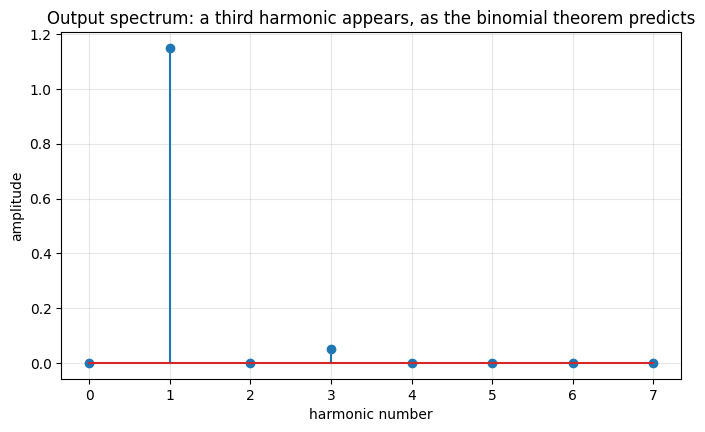

In [18]:
# Distortion of the amplifier y = x + 0.2 x^3 with input x = cos θ
A3 = 0.2
fundamental = 1 + A3 * cos_power_harmonics(3)[1]
third = A3 * cos_power_harmonics(3)[3]
print(f"Predicted by binomial theorem: fundamental = {fundamental:.4f}, third harmonic = {third:.4f}")
print(f"Total harmonic distortion = {100 * third / fundamental:.2f} %")

# Check with the discrete Fourier transform of one sampled period
N = 1024
th = 2 * np.pi * np.arange(N) / N
y = np.cos(th) + A3 * np.cos(th) ** 3
spectrum = 2 * np.abs(np.fft.rfft(y)) / N
print(f"FFT measurement:               fundamental = {spectrum[1]:.4f}, third harmonic = {spectrum[3]:.4f}")

plt.stem(range(8), spectrum[:8])
plt.xlabel("harmonic number")
plt.ylabel("amplitude")
plt.title("Output spectrum: a third harmonic appears, as the binomial theorem predicts")
plt.show()

## 9. Natural response and resonance: eigenvalues and eigenvectors

### 9.1 Series RLC circuit
With state vector $\mathbf x = [i_L,\ v_C]^{\mathsf T}$ and no source, the circuit obeys $\dot{\mathbf x} = M\mathbf x$, where
$$M = \begin{pmatrix} -R/L & -1/L \\ 1/C & 0\end{pmatrix}.$$
If $M = V\Lambda V^{-1}$ (**diagonalisation**), then $\mathbf x(t) = V e^{\Lambda t} V^{-1}\mathbf x(0)$. So the **eigenvalues** decide the behaviour:
* two **real negative** eigenvalues → the circuit settles without oscillating (overdamped)
* a **complex pair** $\lambda = -\alpha \pm j\omega_d$ → it oscillates at $\omega_d$ while decaying at rate $\alpha$ (underdamped)

The eigenvalues are the roots of the **characteristic polynomial** $\det(M - \lambda I) = \lambda^2 + \frac RL\lambda + \frac1{LC} = 0$.

Critical resistance 2√(L/C) = 63.25 Ω

R = 200.0 Ω (overdamped)
  eigenvalues        = [-1948.68   -51.32]
  polynomial roots   = [-1948.68   -51.32]
  λ1 + λ2 = -2000.00 = trace(M) = -2000.00;  λ1·λ2 = 100000.0 = det(M) = 100000.0
  M v = λ v for each eigenvector: True
  max difference from step-by-step simulation = 0.0001 V

R = 20.0 Ω (underdamped)
  eigenvalues        = [-100.+300.j -100.-300.j]
  polynomial roots   = [-100.+300.j -100.-300.j]
  λ1 + λ2 = -200.00 = trace(M) = -200.00;  λ1·λ2 = 100000.0 = det(M) = 100000.0
  M v = λ v for each eigenvector: True
  oscillation frequency ω_d = 300.0 rad/s, decay rate α = 100.0 1/s
  max difference from step-by-step simulation = 0.0012 V


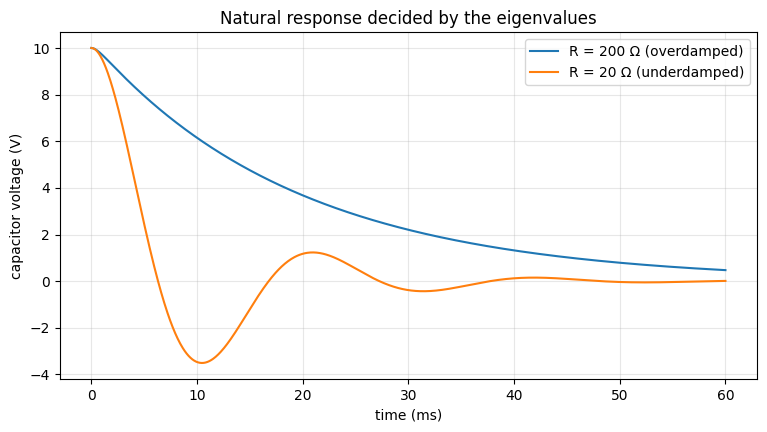

In [19]:
L_RLC, C_RLC = 0.1, 100e-6
R_CRIT = 2 * np.sqrt(L_RLC / C_RLC)
x0 = np.array([0.0, 10.0])              # capacitor starts at 10 V, no current
t = np.linspace(0, 0.06, 1000)
print(f"Critical resistance 2√(L/C) = {R_CRIT:.2f} Ω")

def rlc_matrix(R):
    return np.array([[-R / L_RLC, -1 / L_RLC], [1 / C_RLC, 0.0]])

def simulate(Mx, x_init, times, substeps=100):
    # Step-by-step (Euler) simulation used only to check the eigenvector solution
    out, x = [x_init.copy()], x_init.copy()
    dt = (times[1] - times[0]) / substeps
    for _ in range(len(times) - 1):
        for _ in range(substeps):
            x = x + dt * (Mx @ x)
        out.append(x.copy())
    return np.array(out)

fig, ax = plt.subplots(figsize=(9, 4.5))
for R, label in [(200.0, "overdamped"), (20.0, "underdamped")]:
    M = rlc_matrix(R)
    lam, V = np.linalg.eig(M)
    coeff = np.linalg.solve(V, x0)
    x_t = (V @ (coeff[:, None] * np.exp(np.outer(lam, t)))).real
    x_sim = simulate(M, x0, t)
    print(f"\nR = {R} Ω ({label})")
    print(f"  eigenvalues        = {np.round(lam, 2)}")
    print(f"  polynomial roots   = {np.round(np.roots([1, R / L_RLC, 1 / (L_RLC * C_RLC)]), 2)}")
    print(f"  λ1 + λ2 = {np.sum(lam).real:.2f} = trace(M) = {np.trace(M):.2f};  λ1·λ2 = {np.prod(lam).real:.1f} = det(M) = {np.linalg.det(M):.1f}")
    print(f"  M v = λ v for each eigenvector: {all(np.allclose(M @ V[:, k], lam[k] * V[:, k]) for k in range(2))}")
    if np.iscomplex(lam).any():
        print(f"  oscillation frequency ω_d = {abs(lam[0].imag):.1f} rad/s, decay rate α = {-lam[0].real:.1f} 1/s")
    print(f"  max difference from step-by-step simulation = {np.max(np.abs(x_t[1] - x_sim[:, 1])):.4f} V")
    ax.plot(1e3 * t, x_t[1], label=f"R = {R:.0f} Ω ({label})")
ax.set(xlabel="time (ms)", ylabel="capacitor voltage (V)", title="Natural response decided by the eigenvalues")
ax.legend()
plt.show()

### 9.2 Two coupled resonant circuits
Two identical LC circuits linked by a coupling capacitor $C_c$ obey $M_c\ddot{\mathbf v} + \frac1L\mathbf v = \mathbf 0$, with
$$M_c = \begin{pmatrix} C + C_c & -C_c \\ -C_c & C + C_c \end{pmatrix}.$$
The eigenvectors of the **symmetric** matrix $M_c$ are the **modes**: $[1,1]$ (both circuits in phase) and $[1,-1]$ (in anti-phase). Because $M_c$ is symmetric, its eigenvectors are **orthogonal**. Each mode $k$ oscillates at its own frequency $\omega_k = 1/\sqrt{L\mu_k}$, where $\mu_k$ is the eigenvalue. If only circuit 1 is excited, the energy "beats" back and forth between the two circuits.

mode 1: eigenvector [-0.7071 -0.7071], eigenvalue μ = 100.0 µF, resonance ω = 316.23 rad/s (50.33 Hz)
mode 2: eigenvector [-0.7071  0.7071], eigenvalue μ = 140.0 µF, resonance ω = 267.26 rad/s (42.54 Hz)
Eigenvectors orthogonal: u1·u2 = 0.00e+00
Beat period 2π/|ω1 - ω2| = 0.1283 s


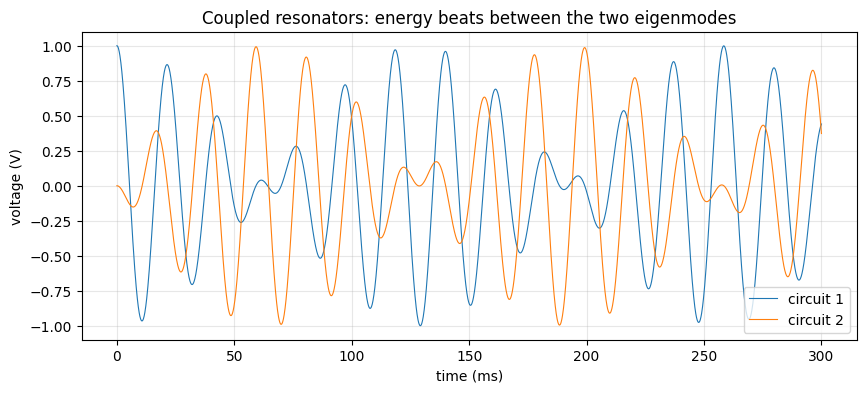

In [20]:
L_C, C_T, C_C = 0.1, 100e-6, 20e-6
Mc = np.array([[C_T + C_C, -C_C], [-C_C, C_T + C_C]])
mu, U = np.linalg.eigh(Mc)                 # eigh: for symmetric matrices, gives orthonormal eigenvectors
omegas = 1 / np.sqrt(L_C * mu)
for k in range(2):
    print(f"mode {k+1}: eigenvector {np.round(U[:, k], 4)}, eigenvalue μ = {mu[k]*1e6:.1f} µF, "
          f"resonance ω = {omegas[k]:.2f} rad/s ({omegas[k]/(2*np.pi):.2f} Hz)")
print(f"Eigenvectors orthogonal: u1·u2 = {U[:, 0] @ U[:, 1]:.2e}")

v_init = np.array([1.0, 0.0])              # only circuit 1 starts charged
q = U.T @ v_init                           # coordinates in the orthonormal eigenbasis
t = np.linspace(0, 0.3, 3000)
v_t = U @ (q[:, None] * np.cos(np.outer(omegas, t)))
print(f"Beat period 2π/|ω1 - ω2| = {2*np.pi/abs(omegas[0]-omegas[1]):.4f} s")

plt.figure(figsize=(10, 4))
plt.plot(1e3 * t, v_t[0], lw=0.8, label="circuit 1")
plt.plot(1e3 * t, v_t[1], lw=0.8, label="circuit 2")
plt.xlabel("time (ms)")
plt.ylabel("voltage (V)")
plt.title("Coupled resonators: energy beats between the two eigenmodes")
plt.legend()
plt.show()

## 10. Cascaded stages: linear transformations

A **two-port network** maps its output (voltage $V_2$, current $I_2$) to its input $(V_1, I_1)$ with a $2\times2$ matrix, its **ABCD matrix**:
$$\begin{pmatrix}V_1\\I_1\end{pmatrix} = \begin{pmatrix}A & B\\ C & D\end{pmatrix}\begin{pmatrix}V_2\\I_2\end{pmatrix}.$$
This is a **linear transformation** $T:\mathbb R^2\to\mathbb R^2$. Basic building blocks:
$$\text{series impedance } Z:\ \begin{pmatrix}1 & Z\\0 & 1\end{pmatrix}, \qquad \text{shunt admittance } Y:\ \begin{pmatrix}1 & 0\\Y & 1\end{pmatrix}.$$
Connecting stages one after another is the **composition** of transformations, which means **matrix multiplication**. Order matters, because matrix multiplication is not commutative. For passive (reciprocal) circuits, $\det = 1$.

In [21]:
def series(z):
    return np.array([[1.0, z], [0.0, 1.0]])

def shunt(y):
    return np.array([[1.0, 0.0], [y, 1.0]])

M_sec = series(1.0) @ shunt(1.0)          # one ladder section: 1 Ω series, then 1 Ω to ground
print("One ladder section (series then shunt):\n", M_sec)
print("Reversed order (shunt then series):\n", shunt(1.0) @ series(1.0))
print(f"det = {np.linalg.det(M_sec):.4f} (reciprocal network)")

# Linearity: T(a u + b w) = a T(u) + b T(w)
u, w = rng.normal(size=2), rng.normal(size=2)
a_, b_ = 2.5, -1.3
print("Linearity holds:", np.allclose(M_sec @ (a_ * u + b_ * w), a_ * (M_sec @ u) + b_ * (M_sec @ w)))

One ladder section (series then shunt):
 [[2. 1.]
 [1. 1.]]
Reversed order (shunt then series):
 [[1. 1.]
 [1. 2.]]
det = 1.0000 (reciprocal network)
Linearity holds: True


### A ladder of $n$ identical sections
$n$ sections give the matrix $M^n$. With **diagonalisation** $M = PDP^{-1}$, the power is easy to compute: $M^n = PD^nP^{-1}$. For our section, the eigenvalues are $\varphi^2 \approx 2.618$ and $\varphi^{-2}\approx0.382$, where $\varphi$ is the golden ratio. The entries of $M^n$ turn out to be **Fibonacci numbers**. The signal drops by the same factor at every stage, so the gain in dB falls on a straight line with slope $-20\log_{10}(\varphi^2)$ per section. The **attenuation constant** is $\gamma = \ln\lambda_{\max}$.

Eigenvalues of one section: [2.618 0.382]   golden ratio squared φ² = 2.618033988749895
n = 1: M^n = [[2, 1], [1, 1]]   V2/V1 = 0.50000
n = 2: M^n = [[5, 3], [3, 2]]   V2/V1 = 0.20000
n = 3: M^n = [[13, 8], [8, 5]]   V2/V1 = 0.07692
n = 4: M^n = [[34, 21], [21, 13]]   V2/V1 = 0.02941
n = 5: M^n = [[89, 55], [55, 34]]   V2/V1 = 0.01124

Attenuation constant γ = ln(λ_max) = 0.9624 nepers per section = 8.360 dB per section
Measured slope of gain vs n (n ≥ 4): -8.359 dB per section


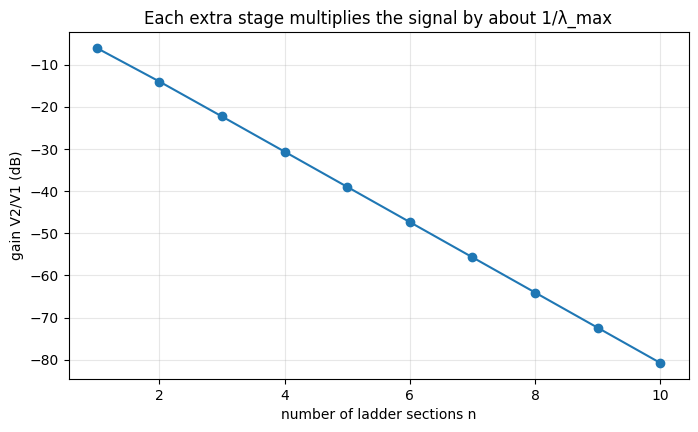

In [22]:
lam, Pm = np.linalg.eig(M_sec)
print("Eigenvalues of one section:", lam, "  golden ratio squared φ² =", ((1 + 5 ** 0.5) / 2) ** 2)

n_values = np.arange(1, 11)
gains_db = []
for n in n_values:
    Mn_eig = Pm @ np.diag(lam ** n) @ np.linalg.inv(Pm)
    Mn = np.linalg.matrix_power(M_sec, n)
    assert np.allclose(Mn_eig, Mn)
    gains_db.append(20 * np.log10(1 / Mn[0, 0]))   # open-circuit output: V2/V1 = 1/A
    if n <= 5:
        print(f"n = {n}: M^n =", Mn.astype(int).tolist(), f"  V2/V1 = {1/Mn[0,0]:.5f}")

gamma = np.log(lam.max())
print(f"\nAttenuation constant γ = ln(λ_max) = {gamma:.4f} nepers per section "
      f"= {20*np.log10(lam.max()):.3f} dB per section")
slope = np.polyfit(n_values[3:], np.array(gains_db)[3:], 1)[0]
print(f"Measured slope of gain vs n (n ≥ 4): {slope:.3f} dB per section")

plt.plot(n_values, gains_db, "o-")
plt.xlabel("number of ladder sections n")
plt.ylabel("gain V2/V1 (dB)")
plt.title("Each extra stage multiplies the signal by about 1/λ_max")
plt.show()

## 11. Safe LED design: inequalities

An LED indicator is powered from $V_s = 9$ V through a resistor $R$. The LED drops about $V_F = 2$ V, so $I = \dfrac{V_s - V_F}{R}$. The design rules are:

1. **Brightness:** $|I - 15\text{ mA}| \le 5\text{ mA}$, i.e. $10\text{ mA} \le I \le 20\text{ mA}$
2. **Resistor power rating:** $P = I^2R = \dfrac{(V_s - V_F)^2}{R} \le 0.25$ W
3. **Tolerance:** real resistors are within ±5% of their marked value, so rules 1 and 2 must hold for every $R' \in [0.95R,\ 1.05R]$

Solving by hand ($R > 0$, so multiplying by $R$ keeps the inequality direction):
$$10^{-2} \le \frac{7}{R} \le 2\times10^{-2} \iff 350 \le R \le 700, \qquad \frac{49}{R} \le 0.25 \iff R \ge 196,$$
$$\text{with tolerance: } 0.95R \ge 350 \text{ and } 1.05R \le 700 \iff 368.4 \le R \le 666.7\ \Omega .$$

In [23]:
VS_LED, VF, I_MIN, I_MAX, P_MAX, TOL = 9.0, 2.0, 0.010, 0.020, 0.25, 0.05

r_lo_bright, r_hi_bright = (VS_LED - VF) / I_MAX, (VS_LED - VF) / I_MIN
r_lo_power = (VS_LED - VF) ** 2 / P_MAX
r_lo = max(r_lo_bright, r_lo_power) / (1 - TOL)
r_hi = r_hi_bright / (1 + TOL)
print(f"Brightness:       {r_lo_bright:.1f} Ω ≤ R ≤ {r_hi_bright:.1f} Ω")
print(f"Power rating:     R ≥ {r_lo_power:.1f} Ω")
print(f"With ±5 % tolerance: {r_lo:.1f} Ω ≤ R ≤ {r_hi:.1f} Ω")

# Standard E12 resistor values that satisfy every inequality
e12 = np.array([1.0, 1.2, 1.5, 1.8, 2.2, 2.7, 3.3, 3.9, 4.7, 5.6, 6.8, 8.2])
standard = np.concatenate([e12 * 10 ** d for d in range(1, 4)])
ok = standard[(standard >= r_lo) & (standard <= r_hi)]
print("Standard E12 values that are safe:", ok)

# Numerical check over a fine grid, including the tolerance extremes
grid = np.linspace(100, 1000, 9001)
def safe(R):
    worst = np.array([R * (1 - TOL), R * (1 + TOL)])
    I = (VS_LED - VF) / worst
    return np.all(np.abs(I - 0.015) <= 0.005) and np.all(I ** 2 * worst <= P_MAX)
safe_grid = grid[[safe(R) for R in grid]]
print(f"Grid search agrees: {safe_grid.min():.1f} Ω to {safe_grid.max():.1f} Ω")

Brightness:       350.0 Ω ≤ R ≤ 700.0 Ω
Power rating:     R ≥ 196.0 Ω
With ±5 % tolerance: 368.4 Ω ≤ R ≤ 666.7 Ω
Standard E12 values that are safe: [390. 470. 560.]
Grid search agrees: 368.5 Ω to 666.6 Ω


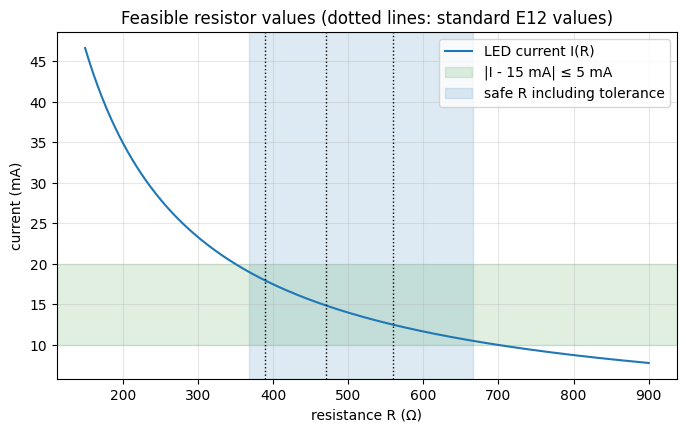

Diode: I(V) ≤ 20 mA  ⇔  V ≤ nV_T ln(1 + I_max/I_S) = 0.6131 V (check: I(0.6131) = 20.000 mA)
Because exp and ln are increasing functions, applying them keeps the direction of the inequality.


In [24]:
R_plot = np.linspace(150, 900, 400)
I_plot = 1e3 * (VS_LED - VF) / R_plot
plt.plot(R_plot, I_plot, label="LED current I(R)")
plt.axhspan(1e3 * I_MIN, 1e3 * I_MAX, color="green", alpha=0.12, label="|I - 15 mA| ≤ 5 mA")
plt.axvspan(r_lo, r_hi, color="C0", alpha=0.15, label="safe R including tolerance")
for R in ok:
    plt.axvline(R, color="k", ls=":", lw=1)
plt.xlabel("resistance R (Ω)")
plt.ylabel("current (mA)")
plt.title("Feasible resistor values (dotted lines: standard E12 values)")
plt.legend()
plt.show()

# A logarithmic inequality: maximum diode voltage that keeps the diode current ≤ 20 mA
v_max = N_IDEAL * VT * np.log(1 + I_MAX / IS)
print(f"Diode: I(V) ≤ 20 mA  ⇔  V ≤ nV_T ln(1 + I_max/I_S) = {v_max:.4f} V "
      f"(check: I({v_max:.4f}) = {1e3*diode_current(v_max):.3f} mA)")
print("Because exp and ln are increasing functions, applying them keeps the direction of the inequality.")

## 12. Results summary and conclusion

In [25]:
summary = {
    "DC node voltages e1, e2, e3 (V)": np.round(e, 4),
    "Battery power = resistor power (W)": round(p_source, 4),
    "Spanning trees = det(A Aᵀ)": len(trees),
    "Independent loops (dim of null space)": null_basis.shape[1],
    "Tellegen vᵀi": f"{v_br @ i_br:.1e}",
    "RC time to 90 % (s)": round(t90, 4),
    "AC output V2 (polar)": f"{abs(V_ac[1]):.4f} V ∠ {np.degrees(np.angle(V_ac[1])):+.2f}°",
    "Filter -3 dB frequency (Hz)": round(freqs[idx], 1),
    "Amplifier THD (%)": round(100 * third / fundamental, 2),
    "Coupled-circuit resonances (rad/s)": np.round(omegas, 2),
    "Ladder attenuation per section (dB)": round(20 * np.log10(lam.max()), 3),
    "Safe LED resistors (E12, Ω)": ok,
}
for key, val in summary.items():
    print(f"{key:40s} {val}")

DC node voltages e1, e2, e3 (V)          [9.2295 5.9249 4.7566]
Battery power = resistor power (W)       16.6231
Spanning trees = det(A Aᵀ)               16
Independent loops (dim of null space)    3
Tellegen vᵀi                             1.3e-15
RC time to 90 % (s)                      0.2303
AC output V2 (polar)                     3.3542 V ∠ -47.53°
Filter -3 dB frequency (Hz)              97.3
Amplifier THD (%)                        4.35
Coupled-circuit resonances (rad/s)       [316.23 267.26]
Ladder attenuation per section (dB)      8.36
Safe LED resistors (E12, Ω)              [390. 470. 560.]


### Conclusion
This project showed that one practical problem, analysing an electronic circuit board, brings together the whole SENG 201 syllabus:

* **Functions, exponential and logarithmic functions** modelled resistors and diodes. Inverse functions and log scales turned the exponential diode law into a straight line.
* **Matrices and systems of linear equations** gave every node voltage and branch current. Gaussian elimination, Cramer's rule, the inverse and NumPy all agreed.
* **Determinants** showed why a ground node is required and counted the spanning trees of the circuit.
* **Vector spaces and subspaces** described the allowed currents (the null space) and voltages (the row space). **Orthogonality** proved Tellegen's power balance. Gram–Schmidt projection cleaned up noisy measurements.
* **Exponential and logarithmic functions** described capacitor charging and gave switching times.
* **Complex numbers and trigonometric functions** turned AC circuits into complex linear systems and produced the filter's frequency response.
* The **binomial theorem** and De Moivre's theorem predicted the harmonics created by a non-linear amplifier, and the FFT confirmed them.
* **Eigenvalues and eigenvectors** decided whether a circuit oscillates and found the resonant modes of coupled circuits.
* **Linear transformations** modelled cascaded two-port stages. Diagonalisation computed long ladders and revealed the golden ratio.
* **Inequalities** produced the safe range of resistor values for the LED, including manufacturing tolerance.

### Possible extensions
* Modified nodal analysis to handle ideal voltage sources and op-amps directly.
* Sensitivity analysis: how node voltages change when one resistor changes (derivative of $Y^{-1}$).
* Three-phase power systems using complex numbers and $3\times3$ symmetric matrices.